In [11]:
# --- Paso 1: diccionario de lugares con coordenadas reales ---
lugares = {
    "Mi casa (San Sebastián)": (-13.5267, -71.9390),
    "UNSAAC": (-13.5200, -71.9578),
    "Coya (Calca)": (-13.3883, -71.9031),
    "Plaza de Armas Cusco": (-13.5168, -71.9788),
}

for nombre, (lat, lon) in lugares.items():
    print(f"{nombre}: lat={lat}, lon={lon}")

Mi casa (San Sebastián): lat=-13.5267, lon=-71.939
UNSAAC: lat=-13.52, lon=-71.9578
Coya (Calca): lat=-13.3883, lon=-71.9031
Plaza de Armas Cusco: lat=-13.5168, lon=-71.9788


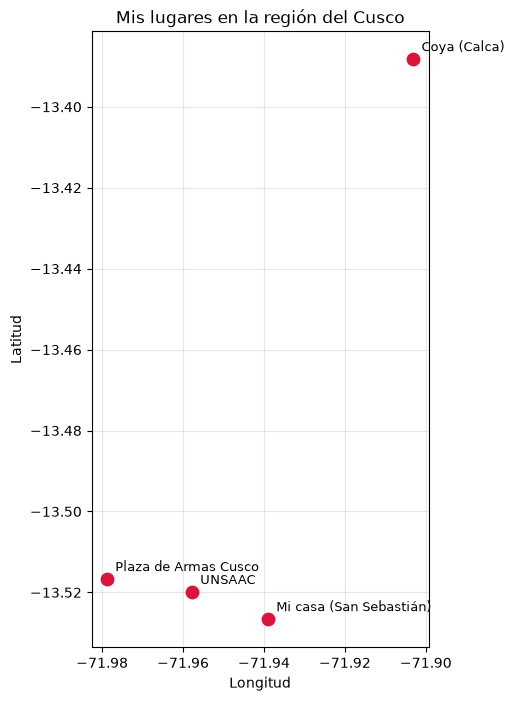

In [12]:
import matplotlib.pyplot as plt

nombres = list(lugares.keys())
lats = [coord[0] for coord in lugares.values()]
lons = [coord[1] for coord in lugares.values()]

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(lons, lats, color="crimson", s=80, zorder=3)

for nombre, lon, lat in zip(nombres, lons, lats):
    ax.annotate(nombre, (lon, lat), textcoords="offset points", xytext=(6, 6), fontsize=9)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Mis lugares en la región del Cusco")
ax.set_aspect("equal")
ax.grid(alpha=0.3)

plt.savefig("mapa_basico.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# --- Paso 1: función de distancia Haversine ---
import math

def distancia_haversine(lat1, lon1, lat2, lon2):
    R = 6371  # radio de la Tierra en km

    lat1_rad, lon1_rad = math.radians(lat1), math.radians(lon1)
    lat2_rad, lon2_rad = math.radians(lat2), math.radians(lon2)

    dlat = lat2_rad - lat1_rad
    dlon = lon2_rad - lon1_rad

    a = math.sin(dlat / 2) ** 2 + math.cos(lat1_rad) * math.cos(lat2_rad) * math.sin(dlon / 2) ** 2
    c = 2 * math.asin(math.sqrt(a))

    return R * c

In [14]:
print(distancia_haversine(-13.5200, -71.9578, -13.5168, -71.9788))

2.2981131997139914


In [15]:
# --- Paso 2: distancias desde TU PRIMER lugar hacia los demás ---
nombres = list(lugares.keys())
primer_nombre = nombres[0]
primer_lat, primer_lon = lugares[primer_nombre]

print(f"Distancias desde {primer_nombre}:\n")
for nombre in nombres[1:]:
    lat, lon = lugares[nombre]
    d = distancia_haversine(primer_lat, primer_lon, lat, lon)
    print(f"  -> {nombre}: {d:.2f} km")

Distancias desde Mi casa (San Sebastián):

  -> UNSAAC: 2.16 km
  -> Coya (Calca): 15.87 km
  -> Plaza de Armas Cusco: 4.44 km


In [16]:
# --- Paso 3: par más cercano y más lejano (todas las combinaciones) ---
from itertools import combinations

distancias = []
for (n1, (lat1, lon1)), (n2, (lat2, lon2)) in combinations(lugares.items(), 2):
    d = distancia_haversine(lat1, lon1, lat2, lon2)
    distancias.append((n1, n2, d))

par_cercano = min(distancias, key=lambda x: x[2])
par_lejano = max(distancias, key=lambda x: x[2])

print(f"Par MÁS CERCANO: {par_cercano[0]} <-> {par_cercano[1]}  ({par_cercano[2]:.2f} km)")
print(f"Par MÁS LEJANO:  {par_lejano[0]} <-> {par_lejano[1]}  ({par_lejano[2]:.2f} km)")

Par MÁS CERCANO: Mi casa (San Sebastián) <-> UNSAAC  (2.16 km)
Par MÁS LEJANO:  Coya (Calca) <-> Plaza de Armas Cusco  (16.47 km)


In [17]:
# --- Paso 1: construir el GeoJSON ---
import json

features = []
for nombre, (lat, lon) in lugares.items():
    feature = {
        "type": "Feature",
        "properties": {
            "nombre": nombre
        },
        "geometry": {
            "type": "Point",
            "coordinates": [lon, lat]  # ¡OJO! GeoJSON usa [longitud, latitud]
        }
    }
    features.append(feature)

geojson_mio = {"type": "FeatureCollection", "features": features}

# --- Paso 2: guardar el archivo ---
with open("mis_lugares.geojson", "w", encoding="utf-8") as f:
    json.dump(geojson_mio, f, indent=2, ensure_ascii=False)

print("Archivo guardado correctamente.")

Archivo guardado correctamente.


In [18]:
# --- Paso 3: reabrir y verificar ---
with open("mis_lugares.geojson", "r", encoding="utf-8") as f:
    geojson_verificado = json.load(f)

print(f"Número de features: {len(geojson_verificado['features'])}")

primer_feature = geojson_verificado["features"][0]
print(f"Primer lugar: {primer_feature['properties']['nombre']}")
print(f"Coordenadas [lon, lat]: {primer_feature['geometry']['coordinates']}")

Número de features: 4
Primer lugar: Mi casa (San Sebastián)
Coordenadas [lon, lat]: [-71.939, -13.5267]


In [19]:
ruta = {
    "type": "Feature",
    "properties": {"nombre": "Ruta Casa-UNSAAC"},
    "geometry": {
        "type": "LineString",
        "coordinates": [
            [-71.9390, -13.5267],  # casa (lon, lat)
            [-71.9578, -13.5200],  # UNSAAC (lon, lat)
        ]
    }
}
features.append(ruta)